# 02 - Model Training & Evaluation

The full training run is `python -m src.train`. It saves the model to `models/` and metrics/plots to
`artifacts/`. This notebook explains the methodology, re-runs a small part of it live (the Logistic
Regression grid search) and presents the saved results.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

## 1. Chronological, match-based split

* **Test set:** the two most recent IPL seasons, held out completely and used once for the final report.
* **Cross-validation:** expanding-window folds by season - fold *k* trains on all seasons before validation
  season *k*. Whole matches stay inside one fold, and the model is never trained on the future.

In [2]:
from src.train import load_chase_states, chronological_split, temporal_cv_splits
states = load_chase_states()
train, test = chronological_split(states, test_seasons=2)
print(f"Train: {train['match_id'].nunique()} matches ({train.season_year.min()}-{train.season_year.max()}), {len(train):,} states")
print(f"Test:  {test['match_id'].nunique()} matches ({sorted(test.season_year.unique())}), {len(test):,} states")
assert not set(train.match_id) & set(test.match_id)
splits = temporal_cv_splits(train, n_splits=4)
pd.DataFrame([{"fold": i + 1, "train seasons": f"{train.iloc[tr].season_year.min()}-{train.iloc[tr].season_year.max()}",
               "validation season": int(train.iloc[va].season_year.iloc[0]), "train states": len(tr),
               "validation states": len(va)} for i, (tr, va) in enumerate(splits)])

Train: 1047 matches (2008-2024), 121,979 states
Test:  138 matches ([np.int64(2025), np.int64(2026)]), 15,914 states


,fold,train seasons,validation season,train states,validation states
0,1,2008-2020,2021,89935,6815
1,2,2008-2021,2022,96750,8693
2,3,2008-2022,2023,105443,8428
3,4,2008-2023,2024,113871,8108


## 2. Pipelines and GridSearchCV (live demo: Logistic Regression)

Every model is a scikit-learn `Pipeline`: a `ColumnTransformer` one-hot encodes teams and venue
(`handle_unknown="infrequent_if_exist"`, so unseen teams/venues map to an "infrequent" column) and scales the numeric
features (for Logistic Regression), followed by the classifier. `GridSearchCV` uses the temporal splits above
and optimises **log loss** - the right objective for probability estimates.

In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from src.feature_engineering import FEATURE_COLUMNS, TARGET_COLUMN
from src.train import build_pipeline, SCORING
search = GridSearchCV(build_pipeline(LogisticRegression(max_iter=3000), scale_numeric=True),
                      {"clf__C": [0.01, 0.1, 1.0]}, scoring=SCORING, refit="log_loss", cv=splits, n_jobs=-1)
search.fit(train[FEATURE_COLUMNS], train[TARGET_COLUMN])
res = pd.DataFrame(search.cv_results_)[["param_clf__C", "mean_test_log_loss", "mean_test_brier", "mean_test_roc_auc"]]
res.assign(mean_test_log_loss=-res.mean_test_log_loss, mean_test_brier=-res.mean_test_brier).round(4)

,param_clf__C,mean_test_log_loss,mean_test_brier,mean_test_roc_auc
0,0.01,0.4549,0.1494,0.8673
1,0.10,0.4772,0.1549,0.8601
2,1.00,0.4841,0.1562,0.8585


## 3. Saved results of the full training run

The full run tuned **Logistic Regression**, **Random Forest** and **Gradient Boosting**
(`HistGradientBoostingClassifier`), plus a base-rate baseline. The model was **selected on CV log loss only**;
test metrics below were computed afterwards on the held-out seasons.

In [4]:
from src.utils import load_json
metrics = load_json(ROOT / "artifacts/metrics.json")
comp = pd.DataFrame(metrics["comparison"])
cols = ["model", "best_params", "cv_log_loss", "test_log_loss", "test_brier", "test_ece", "test_roc_auc",
        "test_accuracy", "test_precision", "test_recall", "test_f1", "selected"]
comp[cols].round(4)

,model,best_params,cv_log_loss,test_log_loss,test_brier,test_ece,test_roc_auc,test_accuracy,test_precision,test_recall,test_f1,selected
0,Baseline (base rate),{},0.6949,0.6891,0.2480,0.0388,0.5000,0.5594,0.5594,1.0000,0.7175,False
1,Logistic Regression,{'C': 0.001},0.4403,0.4201,0.1351,0.0817,0.9009,0.8056,0.8836,0.7514,0.8122,True
2,Random Forest,"{'max_depth': 16, 'min_samples_leaf': 100}",0.4556,0.4530,0.1459,0.1152,0.9033,0.7833,0.9228,0.6687,0.7754,False
3,Gradient Boosting,"{'l2_regularization': 10.0, 'learning_rate': 0...",0.4627,0.4815,0.1547,0.1250,0.8882,0.7769,0.9030,0.6735,0.7715,False


Selected model: Logistic Regression
Calibration decision: none | OOF log loss by method: {'none': 0.44425248947554613, 'sigmoid': 0.44601307211644564, 'isotonic': 0.4523794453720774}


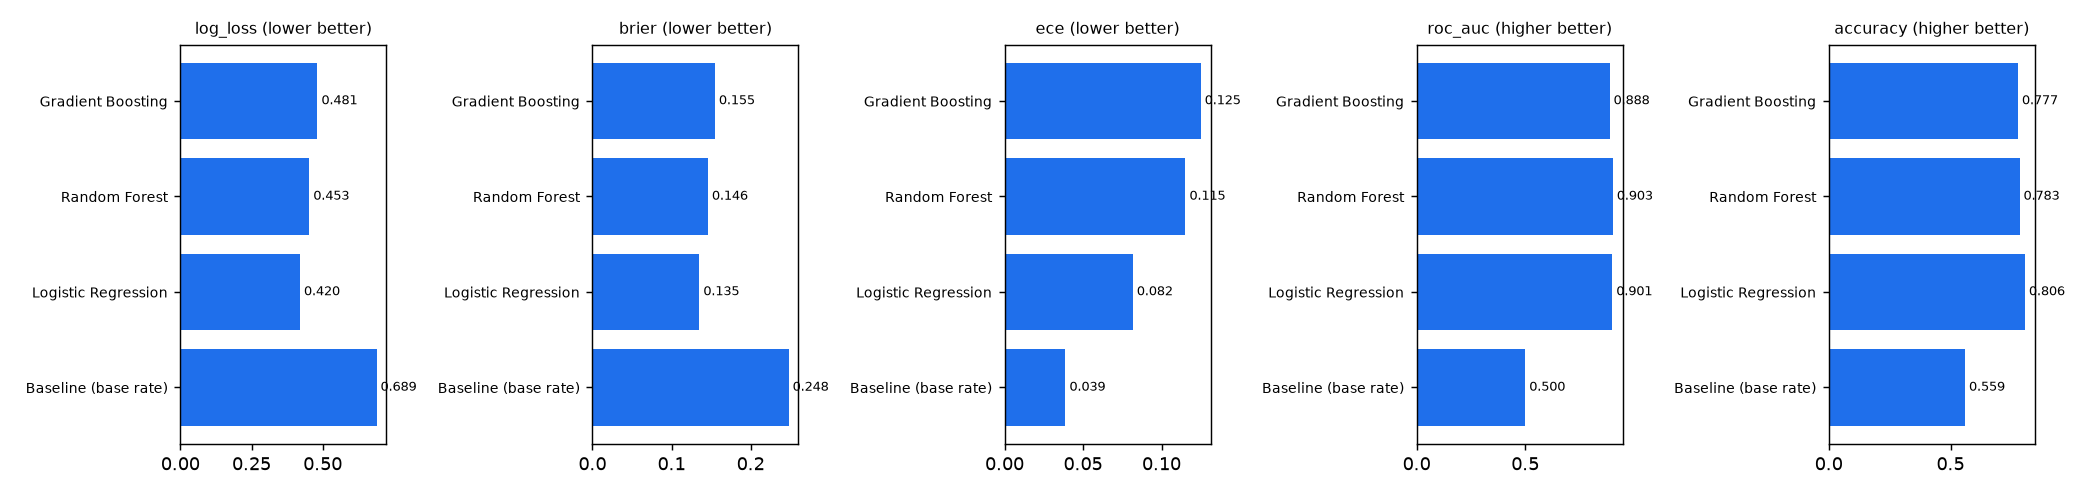

In [5]:
print("Selected model:", metrics["model_name"])
print("Calibration decision:", metrics["calibration"], "| OOF log loss by method:", metrics["calibration_oof_log_loss"])
display(Image(filename=str(ROOT / "artifacts/figures/model_comparison.png")))

## 4. Calibration

A calibration curve compares predicted probabilities with observed win rates. Points on the diagonal mean
"when the model says 70%, the chasing side wins ~70% of the time". Calibration (Platt/sigmoid or isotonic) was
evaluated on **out-of-fold CV predictions** - each calibrator fitted on earlier folds and scored on the next -
and only adopted if it improved log loss, so the test set never influenced it.

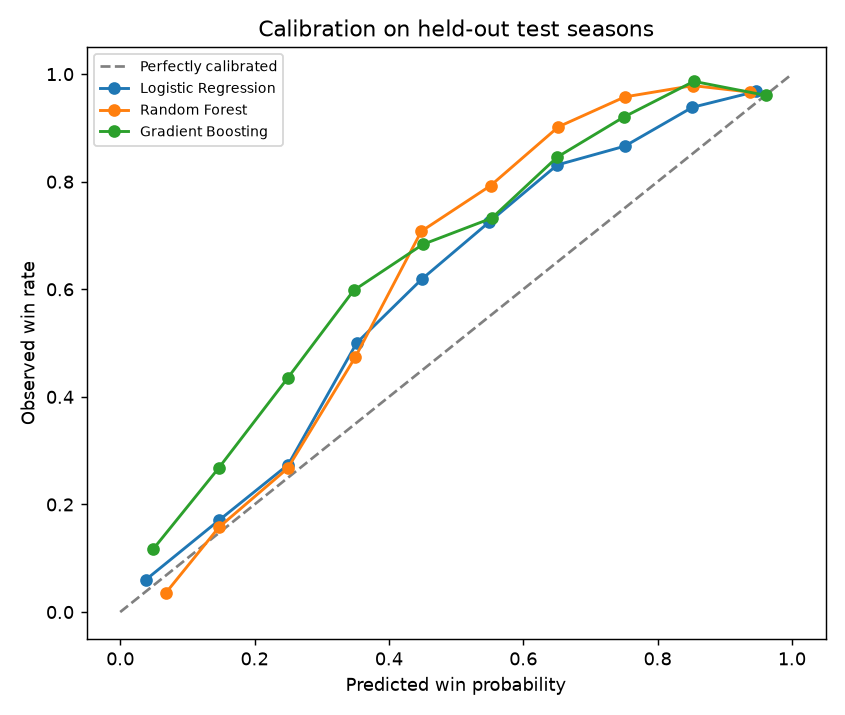

In [6]:
display(Image(filename=str(ROOT / "artifacts/figures/calibration_curves.png")))

## 5. ROC curves, confusion matrix and performance by phase

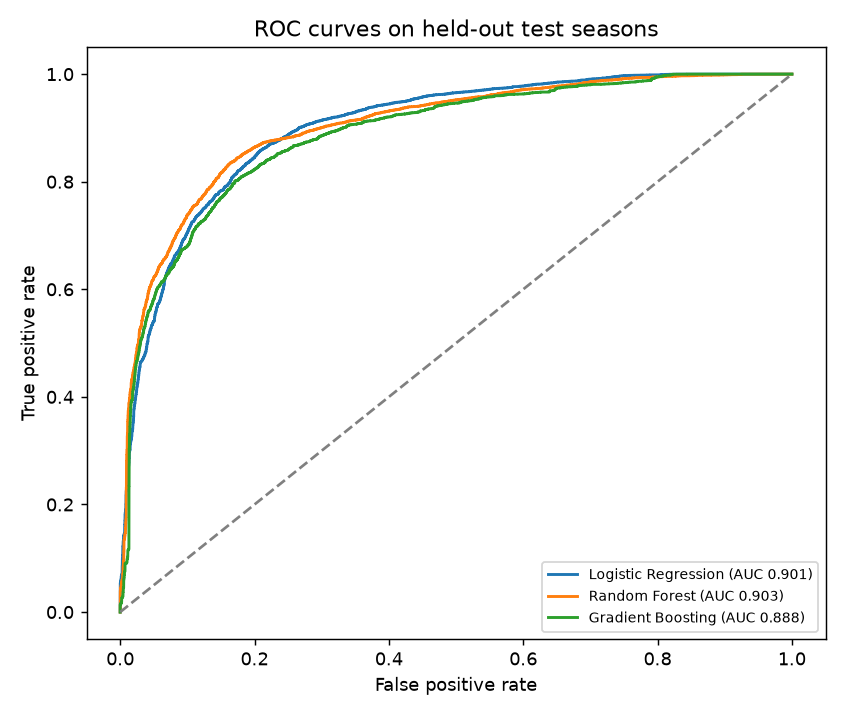

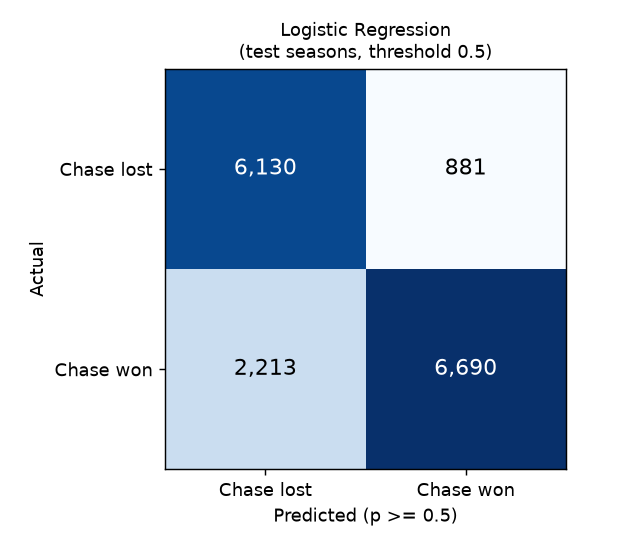

,phase,n_states,accuracy,roc_auc,log_loss,brier
0,Powerplay (0-6 ov),5199,0.7130,0.8409,0.5715,0.1917
1,Middle (6-15 ov),7604,0.8286,0.9133,0.3855,0.1205
2,Death (15-20 ov),3111,0.9039,0.9650,0.2517,0.0763


In [7]:
display(Image(filename=str(ROOT / "artifacts/figures/roc_curves.png")))
display(Image(filename=str(ROOT / "artifacts/figures/confusion_matrix.png")))
pd.DataFrame(metrics["metrics_by_phase"]).round(4)

As expected, predictions get much more accurate as the chase progresses: early in the chase many
outcomes are genuinely uncertain, so a well-calibrated model *should* output probabilities near the base rate.

## 6. What drives the predictions?

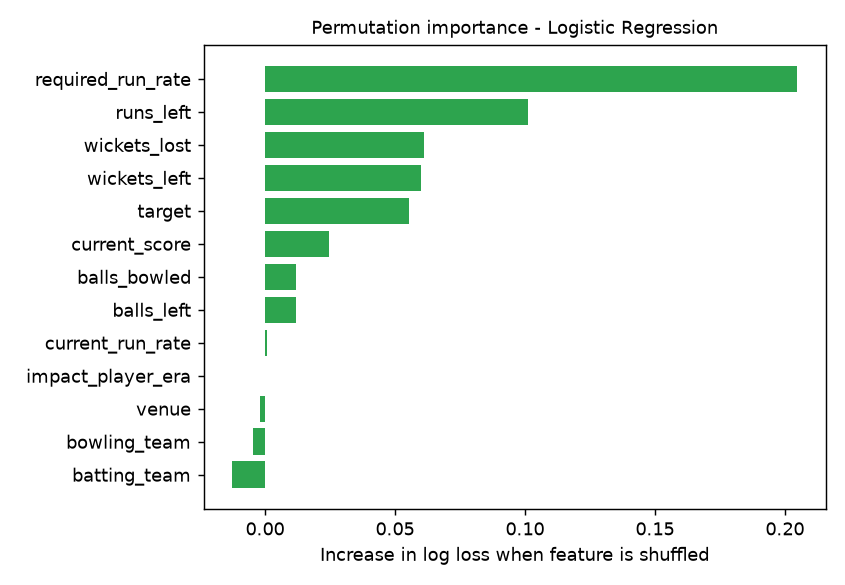

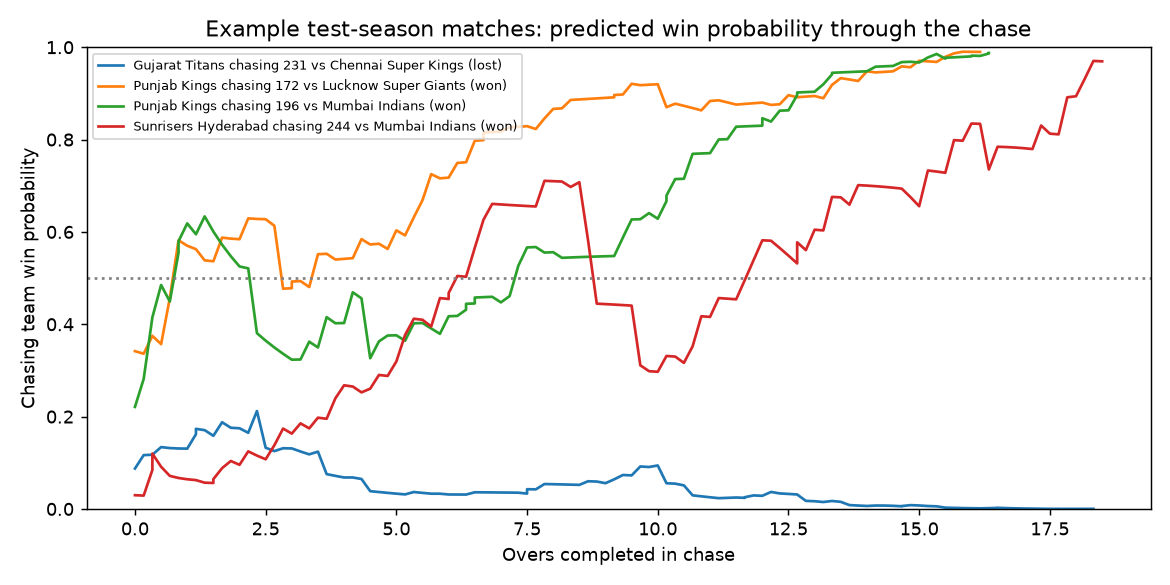

In [8]:
display(Image(filename=str(ROOT / "artifacts/figures/feature_importance.png")))
display(Image(filename=str(ROOT / "artifacts/figures/win_probability_worms.png")))

## 7. Using the saved model for inference

In [9]:
from src.predict import WinProbabilityPredictor, MatchState
predictor = WinProbabilityPredictor.load()
scenarios = [
    MatchState("Mumbai Indians", "Chennai Super Kings", "Wankhede Stadium", 181, 96, 3, 11, 2),
    MatchState("Royal Challengers Bengaluru", "Kolkata Knight Riders", "M Chinnaswamy Stadium", 210, 150, 6, 16, 0),
    MatchState("Gujarat Titans", "Rajasthan Royals", "Narendra Modi Stadium", 165, 140, 2, 17, 0),
    MatchState("Punjab Kings", "Delhi Capitals", "Arun Jaitley Stadium", 190, 190, 5, 19, 3),
]
rows = []
for s in scenarios:
    r = predictor.predict(s)
    rows.append({"batting": s.batting_team, "situation": f"{s.current_score}/{s.wickets_lost} in {s.overs_completed}.{s.balls_in_over} ov, target {s.target}",
                 "status": r.status, "batting win prob": None if r.batting_win_probability is None else round(r.batting_win_probability, 3)})
pd.DataFrame(rows)

C:\Users\Vatsal Ghori\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:440: InconsistentVersionWarning: Trying to unpickle estimator OneHotEncoder from version 1.7.2 when using version 1.7.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
C:\Users\Vatsal Ghori\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:440: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.7.2 when using version 1.7.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
C:\Users\Vatsal Ghori\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:440: InconsistentVersionWarning: Trying

,batting,situation,status,batting win prob
0,Mumbai Indians,"96/3 in 11.2 ov, target 181",in_progress,0.620
1,Royal Challengers Bengaluru,"150/6 in 16.0 ov, target 210",in_progress,0.153
2,Gujarat Titans,"140/2 in 17.0 ov, target 165",in_progress,0.940
3,Punjab Kings,"190/5 in 19.3 ov, target 190",batting_won,NaN


## Limitations

* Only full 20-over chases are modelled (D/L and reduced-overs matches are excluded).
* Team identity is a coarse proxy for squad strength, which changes every season (auctions, injuries).
* Player-level information, pitch, toss, dew and the Impact Player rule are not modelled explicitly.
* Rows from the same match are correlated, so the effective sample size is the number of matches (~1,000 for
  training), not the number of rows.